# Кластеризация ЕГЭ (8.5 если сделаны все задачи)

Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000

Папка с исходными таблицами: C:\Users\programma\Downloads\solution
0.xlsx: 100 точек
1.xlsx: 9999 точек
2.xlsx: 1000 точек
3.xlsx: 10000 точек
4.xlsx: 500 точек
5.xlsx: 9999 точек


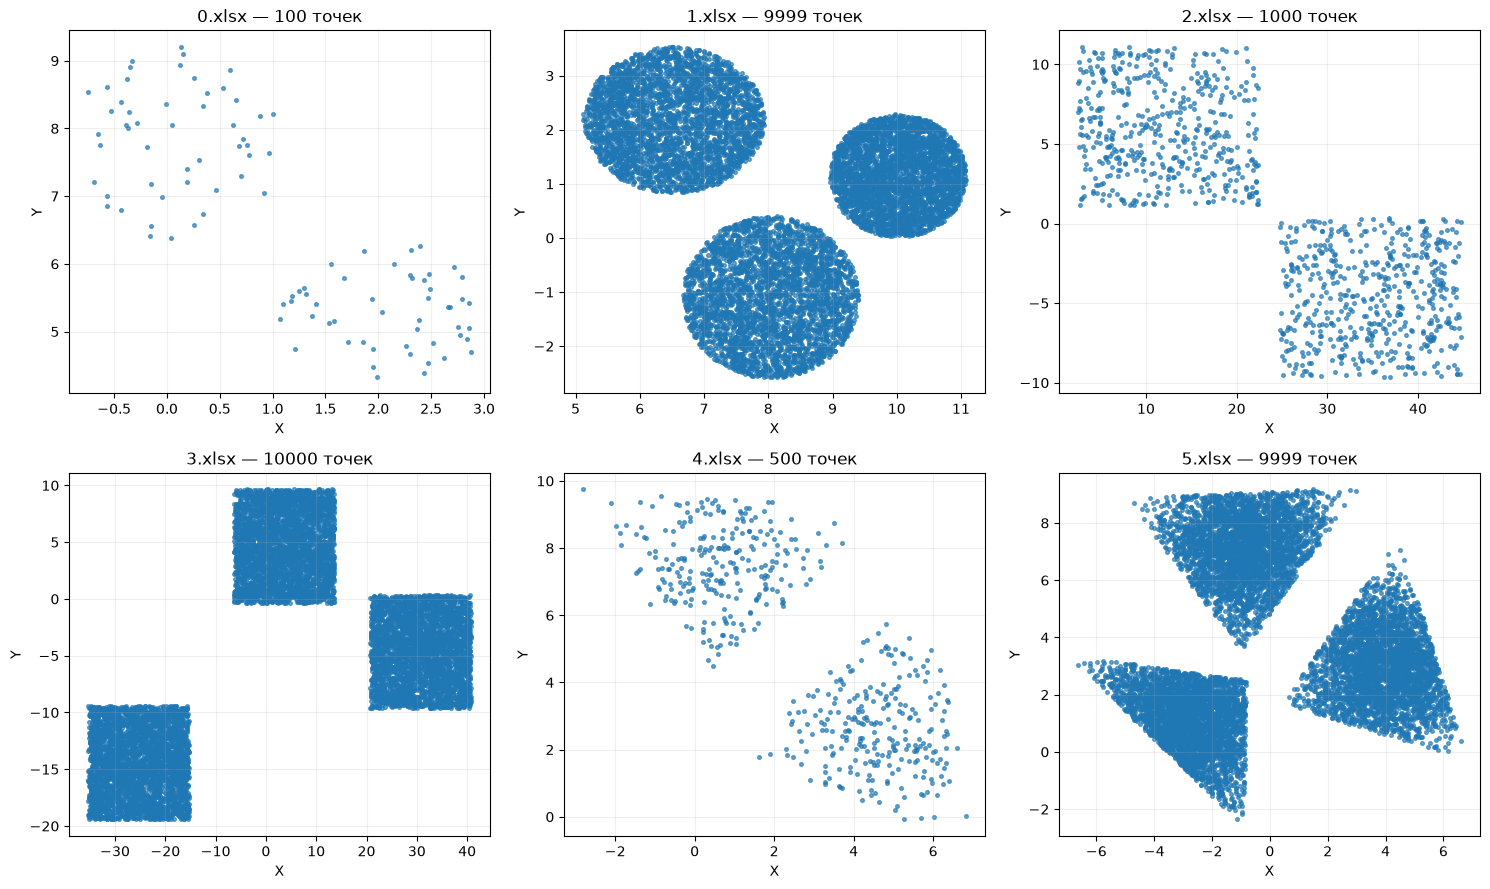

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from IPython.display import display

data_files = ["0.xlsx", "1.xlsx", "2.xlsx", "3.xlsx", "4.xlsx", "5.xlsx"]

def find_data_dir():
    cwd = Path.cwd().resolve()
    roots = [cwd, *list(cwd.parents)[:3]]
    checked = set()

    for root in roots:
        candidates = [root, root / "EGE"]
        for pattern in ("*/0.xlsx", "*/*/0.xlsx", "*/*/*/0.xlsx"):
            try:
                candidates.extend(path.parent for path in root.glob(pattern))
            except (PermissionError, OSError):
                pass

        for folder in candidates:
            folder = folder.resolve()
            if folder in checked:
                continue
            checked.add(folder)
            if all((folder / filename).is_file() for filename in data_files):
                return folder

data_dir = find_data_dir()
print(f"Папка с исходными таблицами: {data_dir}")
data_points = {}

for i, filename in enumerate(data_files):
    header = None if i in (2, 3) else 0
    frame = pd.read_excel(data_dir / filename, header=header, usecols=[0, 1], engine="openpyxl")
    frame = frame.apply(pd.to_numeric, errors="coerce").dropna()
    data_points[i] = frame.to_numpy(dtype=float)
    print(f"{filename}: {len(data_points[i])} точек")

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for i, ax in enumerate(axes.flat):
    points = data_points[i]
    ax.scatter(points[:, 0], points[:, 1], s=7, alpha=0.65)
    ax.set_title(f"{data_files[i]} — {len(points)} точек")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


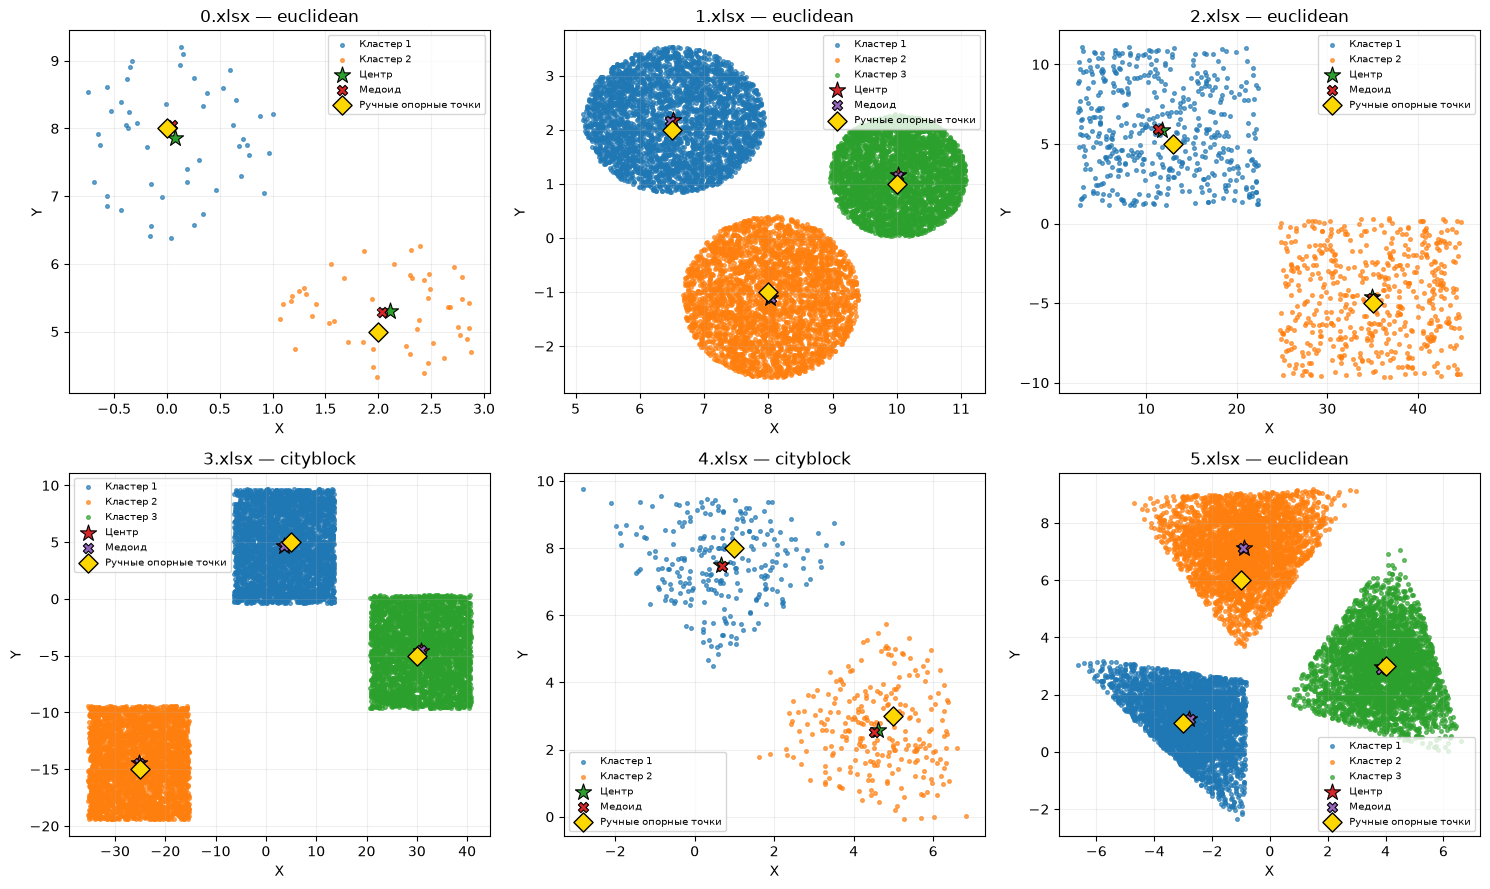

,Файл,Кластер,Точек,Центр X,Центр Y,Медоид X,Медоид Y,Сумма расстояний до медоида,Метрика
0,0.xlsx,1,50,0.08026,7.85281,0.04811,8.05305,43.29877,Евклидова
1,0.xlsx,2,50,2.10668,5.29861,2.03390,5.28930,36.15344,Евклидова
2,1.xlsx,1,3333,6.51286,2.17236,6.46998,2.16976,3086.31680,Евклидова
3,1.xlsx,2,3333,8.03065,-1.11216,8.04007,-1.10871,3177.15907,Евклидова
4,1.xlsx,3,3333,10.01810,1.17025,10.02254,1.15420,2456.77575,Евклидова
5,2.xlsx,1,476,11.79164,5.89801,11.33408,5.96596,2817.18477,Евклидова
6,2.xlsx,2,524,34.97638,-4.61669,34.92635,-4.69528,3092.48753,Евклидова
7,3.xlsx,1,3284,3.60554,4.62156,3.51791,4.65370,24396.13199,Манхэттенская
8,3.xlsx,2,3429,-25.29109,-14.40960,-25.13076,-14.41333,25631.37320,Манхэттенская
9,3.xlsx,3,3287,30.79670,-4.60510,30.84953,-4.51720,24365.73552,Манхэттенская


,Файл,Среднее центров X × 1000,Среднее центров Y × 1000
0,0.xlsx,1093.47093,6575.71132
1,1.xlsx,8187.20291,743.48496
2,2.xlsx,23384.00832,640.66241
3,3.xlsx,3037.04837,-4797.71144
4,4.xlsx,2631.11864,5048.73179
5,5.xlsx,62.06749,3741.02621


In [7]:
manual_anchors = {
    0: np.array([[0, 8], [2, 5]]),
    1: np.array([[6.5, 2], [8, -1], [10, 1]]),
    2: np.array([[13, 5], [35, -5]]),
    3: np.array([[5, 5], [-25, -15], [30, -5]]),
    4: np.array([[1, 8], [5, 3]]),
    5: np.array([[-3, 1], [-1, 6], [4, 3]]),
}

metrics = {i: ("cityblock" if i in (3, 4) else "euclidean") for i in range(6)}
manual_labels = {}

for i, points in data_points.items():
    distances = cdist(points, manual_anchors[i], metric=metrics[i])
    manual_labels[i] = distances.argmin(axis=1)

def distance_sums(points, metric, chunk_size=512):
    if metric == "cityblock":
        sums = np.zeros(len(points), dtype=float)
        for column in range(points.shape[1]):
            values = points[:, column]
            order = np.argsort(values)
            sorted_values = values[order]
            prefix = np.concatenate(([0.0], np.cumsum(sorted_values)))
            indices = np.arange(len(values))
            left = sorted_values * indices - prefix[:-1]
            right = (prefix[-1] - prefix[1:]) - sorted_values * (len(values) - indices - 1)
            sums[order] += left + right
        return sums
    sums = np.empty(len(points), dtype=float)
    for start in range(0, len(points), chunk_size):
        block = points[start:start + chunk_size]
        sums[start:start + len(block)] = cdist(block, points, metric="euclidean").sum(axis=1)
    return sums

cluster_summary_rows = []
mean_centers_rows = []
manual_results = {}

for i, points in data_points.items():
    labels = manual_labels[i]
    centers = []
    medoids = []
    medoid_objectives = []
    counts = []

    for cluster_id in range(len(manual_anchors[i])):
        cluster_points = points[labels == cluster_id]
        counts.append(len(cluster_points))

        center = cluster_points.mean(axis=0)
        centers.append(center)

        sums = distance_sums(cluster_points, metrics[i])
        medoid_idx = int(np.argmin(sums))
        medoid = cluster_points[medoid_idx]
        medoids.append(medoid)
        medoid_objective = float(sums[medoid_idx])
        medoid_objectives.append(medoid_objective)

        cluster_summary_rows.append({
            "Файл": data_files[i],
            "Кластер": cluster_id + 1,
            "Точек": len(cluster_points),
            "Центр X": center[0],
            "Центр Y": center[1],
            "Медоид X": medoid[0],
            "Медоид Y": medoid[1],
            "Сумма расстояний до медоида": medoid_objective,
            "Метрика": "Манхэттенская" if metrics[i] == "cityblock" else "Евклидова",
        })

    centers = np.asarray(centers)
    medoids = np.asarray(medoids)
    mean_center_x1000 = centers.mean(axis=0) * 1000

    manual_results[i] = {
        "centers": centers,
        "medoids": medoids,
        "medoid_objectives": medoid_objectives,
        "counts": counts,
        "mean_centers_x1000": mean_center_x1000,
    }
    mean_centers_rows.append({
        "Файл": data_files[i],
        "Среднее центров X × 1000": mean_center_x1000[0],
        "Среднее центров Y × 1000": mean_center_x1000[1],
    })

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for i, ax in enumerate(axes.flat):
    points = data_points[i]
    labels = manual_labels[i]
    for cluster_id in range(len(manual_anchors[i])):
        mask = labels == cluster_id
        ax.scatter(
            points[mask, 0], points[mask, 1],
            s=7, alpha=0.65, label=f"Кластер {cluster_id + 1}"
        )
    centers = manual_results[i]["centers"]
    medoids = manual_results[i]["medoids"]
    ax.scatter(centers[:, 0], centers[:, 1], marker="*", s=150,
               edgecolors="black", linewidths=0.8, label="Центр")
    ax.scatter(medoids[:, 0], medoids[:, 1], marker="X", s=55,
               edgecolors="black", linewidths=0.8, label="Медоид")
    anchors = manual_anchors[i]
    ax.scatter(
        anchors[:, 0], anchors[:, 1],
        marker="D", s=95, color="gold", edgecolors="black",
        linewidths=1.0, label="Ручные опорные точки", zorder=6,
    )
    ax.set_title(f"{data_files[i]} — {metrics[i]}")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

cluster_summary = pd.DataFrame(cluster_summary_rows)
display(cluster_summary.round(5))

mean_centers_summary = pd.DataFrame(mean_centers_rows)
display(mean_centers_summary.round(5))


# Кластеризация (0.75 за каждый алгоритм на всех данных)

На предложенных распределениях данных проверьте предложенные алгоритмы. Постройте графики кластеризации для каждой пары алгоритм-данные, разные кластеры покрасьте разным цветом. Воспользуйтесь sklearn реализациями. Параметры кластеризации для разных алгоритмов подберите такие, чтобы алгоритмы можно было сравнивать (по возможности одинаковое количество кластеров и т.д.)

In [3]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler
from itertools import cycle, islice

In [4]:
two_means = cluster.MiniBatchKMeans
dbscan = cluster.DBSCAN

clustering_algorithms = (
    ("MiniBatch KMeans", two_means),
    ("DBSCAN", dbscan),
)


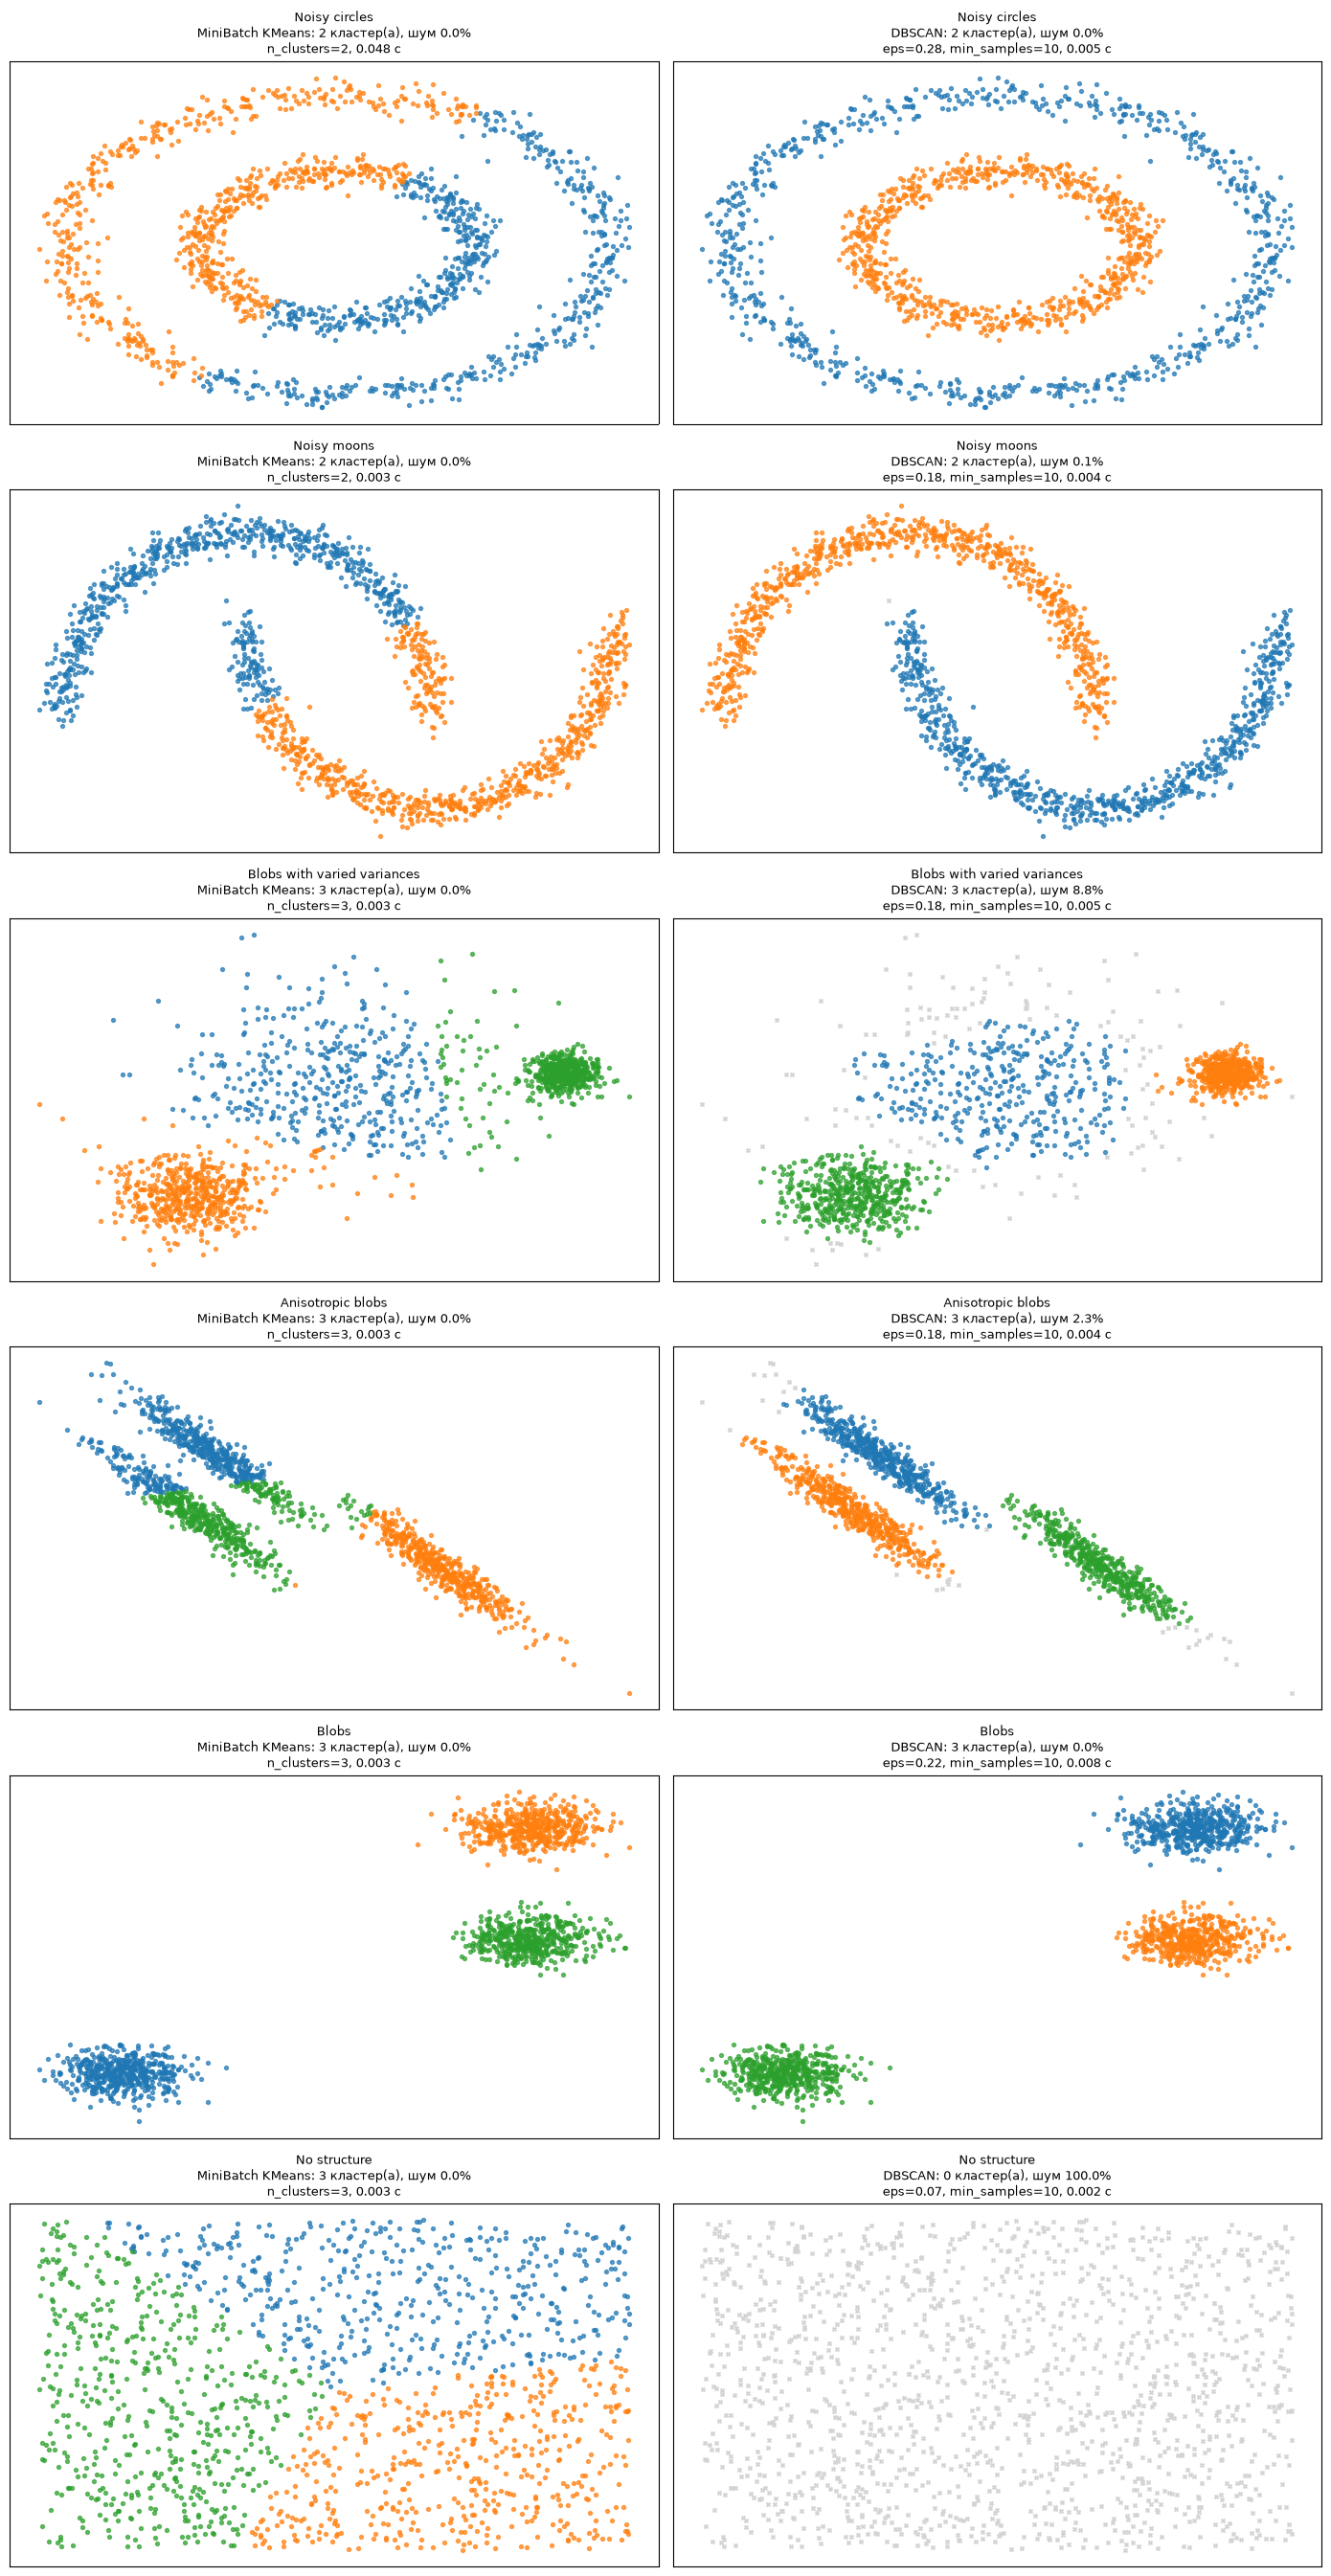

,Набор данных,Алгоритм,Кластеров,Доля шума,"Время, с",Параметры
0,Noisy circles,MiniBatch KMeans,2,0.0000,0.0481,n_clusters=2
1,Noisy circles,DBSCAN,2,0.0000,0.0050,"eps=0.28, min_samples=10"
2,Noisy moons,MiniBatch KMeans,2,0.0000,0.0034,n_clusters=2
3,Noisy moons,DBSCAN,2,0.0007,0.0039,"eps=0.18, min_samples=10"
4,Blobs with varied variances,MiniBatch KMeans,3,0.0000,0.0031,n_clusters=3
5,Blobs with varied variances,DBSCAN,3,0.0880,0.0049,"eps=0.18, min_samples=10"
6,Anisotropic blobs,MiniBatch KMeans,3,0.0000,0.0034,n_clusters=3
7,Anisotropic blobs,DBSCAN,3,0.0233,0.0042,"eps=0.18, min_samples=10"
8,Blobs,MiniBatch KMeans,3,0.0000,0.0032,n_clusters=3
9,Blobs,DBSCAN,3,0.0000,0.0077,"eps=0.22, min_samples=10"


In [5]:
np.random.seed(0)

n_samples = 1500
noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = np.random.rand(n_samples, 2), None

random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

varied = datasets.make_blobs(
    n_samples=n_samples,
    cluster_std=[1.0, 2.5, 0.5],
    random_state=random_state,
)

datasets_to_cluster = [
    ("Noisy circles", noisy_circles, {"n_clusters": 2, "eps": 0.28, "min_samples": 10}),
    ("Noisy moons", noisy_moons, {"n_clusters": 2, "eps": 0.18, "min_samples": 10}),
    ("Blobs with varied variances", varied, {"n_clusters": 3, "eps": 0.18, "min_samples": 10}),
    ("Anisotropic blobs", aniso, {"n_clusters": 3, "eps": 0.18, "min_samples": 10}),
    ("Blobs", blobs, {"n_clusters": 3, "eps": 0.22, "min_samples": 10}),
    ("No structure", no_structure, {"n_clusters": 3, "eps": 0.07, "min_samples": 10}),
]

fig, axes = plt.subplots(
    nrows=len(datasets_to_cluster),
    ncols=len(clustering_algorithms),
    figsize=(14, 27),
)
algorithm_results = []

for row, (dataset_name, dataset, params) in enumerate(datasets_to_cluster):
    X, _ = dataset
    X = StandardScaler().fit_transform(X)

    for col, (algorithm_name, algorithm_class) in enumerate(clustering_algorithms):
        if algorithm_name == "MiniBatch KMeans":
            algorithm = algorithm_class(
                n_clusters=params["n_clusters"],
                random_state=0,
                n_init=10,
                batch_size=256,
                max_iter=200,
            )
            algorithm_parameters = f'n_clusters={params["n_clusters"]}'
        else:
            algorithm = algorithm_class(
                eps=params["eps"],
                min_samples=params["min_samples"],
            )
            algorithm_parameters = (
                f'eps={params["eps"]}, min_samples={params["min_samples"]}'
            )

        start_time = time.perf_counter()
        labels = algorithm.fit_predict(X)
        elapsed = time.perf_counter() - start_time

        found_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_fraction = float(np.mean(labels == -1))

        ax = axes[row, col]
        for cluster_label in sorted(np.unique(labels)):
            mask = labels == cluster_label
            if cluster_label == -1:
                ax.scatter(
                    X[mask, 0], X[mask, 1],
                    s=8, marker="x", color="lightgray", label="Шум"
                )
            else:
                ax.scatter(
                    X[mask, 0], X[mask, 1],
                    s=8, alpha=0.7, label=f"Кластер {cluster_label + 1}"
                )

        ax.set_title(
            f"{dataset_name}\n{algorithm_name}: "
            f"{found_clusters} кластер(а), шум {noise_fraction:.1%}\n"
            f"{algorithm_parameters}, {elapsed:.3f} с",
            fontsize=9,
        )
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(alpha=0.15)

        algorithm_results.append({
            "Набор данных": dataset_name,
            "Алгоритм": algorithm_name,
            "Кластеров": found_clusters,
            "Доля шума": noise_fraction,
            "Время, с": elapsed,
            "Параметры": algorithm_parameters,
        })

fig.tight_layout()
plt.show()

algorithm_summary = pd.DataFrame(algorithm_results)
display(algorithm_summary.round(4))
